In [1]:
import numpy as np
import matplotlib.pyplot as plt

========== MDP 参数 ==========
折现因子 gamma = 0.9

动作 a1 转移矩阵：
 [[0.         0.5        0.5       ]
 [0.25       0.5        0.25      ]
 [0.16666667 0.16666667 0.66666667]]

动作 a2 转移矩阵：
 [[0.5        0.25       0.25      ]
 [0.16666667 0.66666667 0.16666667]
 [0.125      0.125      0.75      ]]

期望即时奖励矩阵：
 [[-1.5    0.75 ]
 [ 0.     0.   ]
 [ 0.5   -0.375]]

========== Value Iteration ==========
最优价值函数：
[4.68331808 3.71557615 4.39944711]
最优策略：
s1 : a2
s2 : a1
s3 : a1
迭代次数： 85

========== Gauss-Seidel ==========
最优价值函数：
[4.68347082 3.71574615 4.39962654]
最优策略：
s1 : a2
s2 : a1
s3 : a1
迭代次数： 70


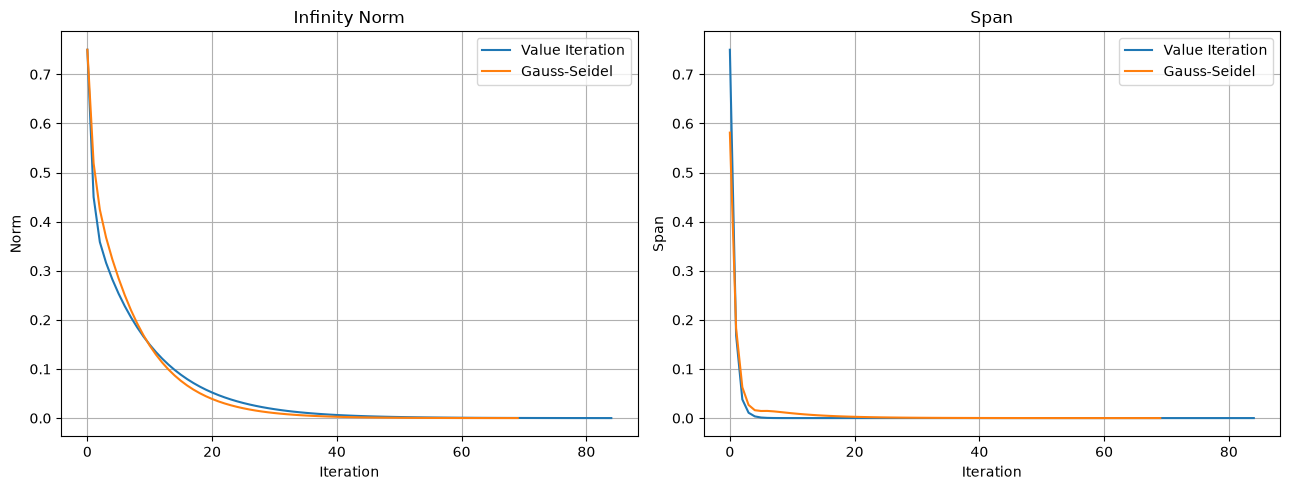

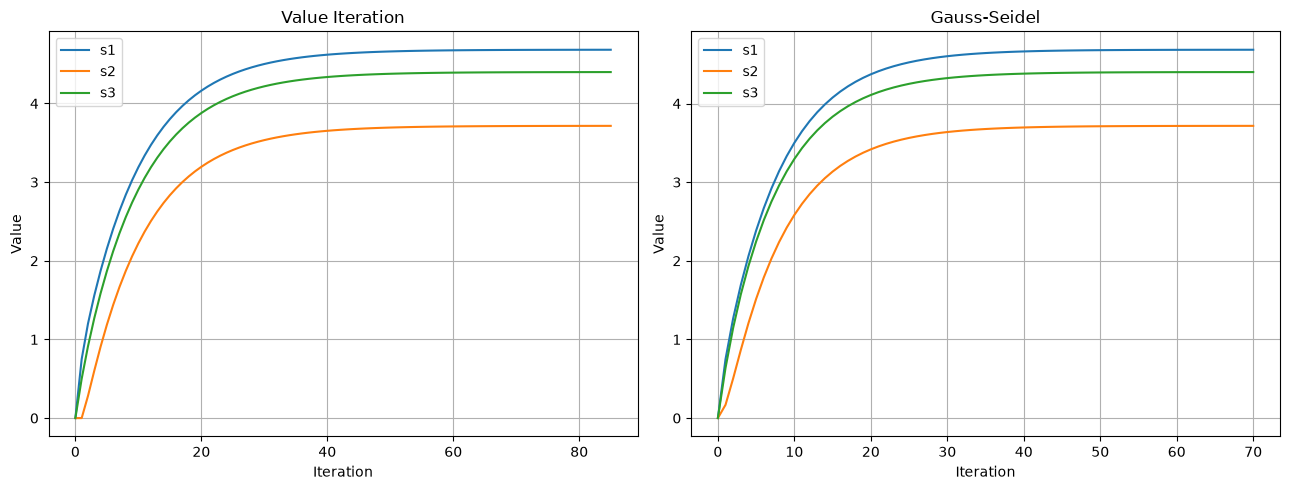


Value Iteration
Bellman residual: [5.52887176e-05 5.52887176e-05 5.52887176e-05]
Infinity norm error bound: 0.000552887176361594
Span error bound: 8.881784197001254e-15

Gauss-Seidel
Bellman residual: [4.99061926e-05 3.65236979e-05 3.19283421e-05]
Infinity norm error bound: 0.0004990619262290609
Span error bound: 0.00017977850517603147


In [3]:
gamma = 0.9

n_states = 3
n_actions = 2

states = ['s1', 's2', 's3']
actions = ['a1', 'a2']

# P[action, state, next_state]
# 第一个动作 a1 的转移矩阵
P1 = np.array([
    [0,   1/2, 1/2],
    [1/4, 1/2, 1/4],
    [1/6, 1/6, 2/3]
])

# 第二个动作 a2 的转移矩阵
P2 = np.array([
    [1/2, 1/4, 1/4],
    [1/6, 2/3, 1/6],
    [1/8, 1/8, 3/4]
])

P = np.array([P1, P2])

# ==================================================
# 2. 计算期望即时奖励
# ==================================================

# 原始奖励：
# r(s_i, a_i1, s_j) = i-j
# r(s_i, a_i2, s_j) = j-i

R_raw = np.zeros((n_states, n_actions, n_states))

for i in range(n_states):
    for j in range(n_states):
        R_raw[i, 0, j] = i - j
        R_raw[i, 1, j] = j - i

# R[state, action]
R = np.sum(P.transpose(1, 0, 2) * R_raw, axis=2)

print("========== MDP 参数 ==========")
print("折现因子 gamma =", gamma)
print("\n动作 a1 转移矩阵：\n", P1)
print("\n动作 a2 转移矩阵：\n", P2)
print("\n期望即时奖励矩阵：\n", R)


# ==================================================
# 3. Bellman 最优算子
# ==================================================

def get_Q(V):
    """
    计算每个状态、每个动作的 Q 值
    输出形状：(n_states, n_actions)
    """
    expected_future = np.einsum(
        'sak,k->sa',
        P.transpose(1, 0, 2),
        V
    )

    return R + gamma * expected_future


def bellman(V):
    """
    Bellman 最优算子
    """
    return np.max(get_Q(V), axis=1)


# ==================================================
# 4. 普通值迭代 Value Iteration
# ==================================================

def value_iteration(epsilon=0.01, max_iter=10000):

    V = np.zeros(n_states)

    norm_history = []
    span_history = []
    value_history = [V.copy()]
    residual_history = []

    for k in range(max_iter):

        # 同步更新：所有状态使用上一轮 V
        V_new = bellman(V)

        delta = V_new - V

        # 无穷范数
        norm_delta = np.max(np.abs(delta))

        # Span
        span_delta = np.max(delta) - np.min(delta)

        norm_history.append(norm_delta)
        span_history.append(span_delta)

        V = V_new
        value_history.append(V.copy())

        # Bellman 残差
        residual = bellman(V) - V
        residual_norm = np.max(np.abs(residual))

        residual_history.append(residual_norm)

        # 价值函数误差上界
        error_bound = residual_norm / (1 - gamma)

        # 贪心策略性能损失上界
        policy_bound = (
            2 * gamma / (1 - gamma) * error_bound
        )

        if policy_bound <= epsilon:
            break

    # 提取贪心策略
    policy = np.argmax(get_Q(V), axis=1)

    return (
        V,
        policy,
        np.array(norm_history),
        np.array(span_history),
        np.array(value_history),
        np.array(residual_history)
    )


# ==================================================
# 5. Gauss-Seidel 迭代
# ==================================================

def gauss_seidel(epsilon=0.01, max_iter=10000):

    V = np.zeros(n_states)

    norm_history = []
    span_history = []
    value_history = [V.copy()]
    residual_history = []

    for k in range(max_iter):

        V_old = V.copy()

        # 按照 s1, s2, s3 的顺序依次更新
        for s in range(n_states):

            # 这里直接使用当前最新的 V
            Q = R[s] + gamma * P[:, s, :] @ V

            V[s] = np.max(Q)

        delta = V - V_old

        # 无穷范数
        norm_delta = np.max(np.abs(delta))

        # Span
        span_delta = np.max(delta) - np.min(delta)

        norm_history.append(norm_delta)
        span_history.append(span_delta)

        value_history.append(V.copy())

        # 使用 Bellman 残差判断收敛
        residual = bellman(V) - V
        residual_norm = np.max(np.abs(residual))

        residual_history.append(residual_norm)

        error_bound = residual_norm / (1 - gamma)

        policy_bound = (
            2 * gamma / (1 - gamma) * error_bound
        )

        if policy_bound <= epsilon:
            break

    policy = np.argmax(get_Q(V), axis=1)

    return (
        V,
        policy,
        np.array(norm_history),
        np.array(span_history),
        np.array(value_history),
        np.array(residual_history)
    )


# ==================================================
# 6. 执行两种算法
# ==================================================

epsilon = 0.01

result_vi = value_iteration(epsilon)
result_gs = gauss_seidel(epsilon)

V_vi, policy_vi = result_vi[:2]
V_gs, policy_gs = result_gs[:2]


# ==================================================
# 7. 输出计算结果
# ==================================================

print("\n========== Value Iteration ==========")

print("最优价值函数：")
print(V_vi)

print("最优策略：")
for i in range(n_states):
    print(states[i], ":", actions[policy_vi[i]])

print("迭代次数：", len(result_vi[2]))

print("\n========== Gauss-Seidel ==========")

print("最优价值函数：")
print(V_gs)

print("最优策略：")
for i in range(n_states):
    print(states[i], ":", actions[policy_gs[i]])

print("迭代次数：", len(result_gs[2]))


# ==================================================
# 8. 绘制范数和跨度随迭代次数的变化
# ==================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 无穷范数
axes[0].plot(
    result_vi[2],
    label='Value Iteration'
)

axes[0].plot(
    result_gs[2],
    label='Gauss-Seidel'
)

axes[0].set_title('Infinity Norm')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Norm')
axes[0].legend()
axes[0].grid()

# Span
axes[1].plot(
    result_vi[3],
    label='Value Iteration'
)

axes[1].plot(
    result_gs[3],
    label='Gauss-Seidel'
)

axes[1].set_title('Span')
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Span')
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()


# ==================================================
# 9. 绘制价值函数随迭代次数的变化
# ==================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for i in range(n_states):

    axes[0].plot(
        result_vi[4][:, i],
        label=states[i]
    )

    axes[1].plot(
        result_gs[4][:, i],
        label=states[i]
    )

axes[0].set_title('Value Iteration')
axes[1].set_title('Gauss-Seidel')

for ax in axes:
    ax.set_xlabel('Iteration')
    ax.set_ylabel('Value')
    ax.legend()
    ax.grid()

plt.tight_layout()
plt.show()


# ==================================================
# 10. 输出最终 Bellman 残差及误差界
# ==================================================

def print_error_bounds(result, name):

    V = result[0]

    residual = bellman(V) - V

    norm_bound = (
        np.max(np.abs(residual)) / (1-gamma)
    )

    span_bound = (
        (np.max(residual)-np.min(residual))
        / (1-gamma)
    )

    print(f"\n{name}")
    print("Bellman residual:", residual)
    print("Infinity norm error bound:", norm_bound)
    print("Span error bound:", span_bound)


print_error_bounds(result_vi, "Value Iteration")
print_error_bounds(result_gs, "Gauss-Seidel")


In [4]:
# 确保完整执行30次，不提前停止
result_vi = value_iteration(epsilon=0, max_iter=30)
result_gs = gauss_seidel(epsilon=0, max_iter=30)

In [5]:

# ==================================================
# (c) 第10、20、30次迭代的误差界
# ==================================================

def calculate_bounds(result, name):

    value_history = result[4]

    print(f"\n========== {name} ==========")

    for k in [10, 20, 30]:

        # 取得第k次迭代后的价值函数
        V_k = value_history[k]

        # 计算Bellman残差
        residual = bellman(V_k) - V_k

        # 无穷范数
        norm_residual = np.max(np.abs(residual))

        # Span
        span_residual = np.max(residual) - np.min(residual)

        # 误差界
        norm_bound = norm_residual / (1 - gamma)

        span_bound = span_residual / (1 - gamma)

        print(f"\n第{k}次迭代：")
        print("V_k =", V_k)
        print("Bellman Residual =", residual)

        print("Infinity Norm Bound =", norm_bound)
        print("Span Bound =", span_bound)


# 分别计算两种算法的误差界
calculate_bounds(result_vi, "Value Iteration")

calculate_bounds(result_gs, "Gauss-Seidel")



========== Value Iteration ==========

第10次迭代：
V_k = [3.18953935 2.22179774 2.90565754]
Bellman Residual = [0.1494308  0.14943055 0.14943755]
Infinity Norm Bound = 1.4943754530476518
Span Bound = 6.998905465849249e-05

第20次迭代：
V_k = [4.16282816 3.19508623 3.87895719]
Bellman Residual = [0.05210428 0.05210428 0.05210428]
Infinity Norm Bound = 0.521042807548371
Span Bound = 3.7808023378715924e-09

第30次迭代：
V_k = [4.50219458 3.53445264 4.21832361]
Bellman Residual = [0.01816764 0.01816764 0.01816764]
Infinity Norm Bound = 0.1816763926081855
Span Bound = 2.0428103653102885e-13

========== Gauss-Seidel ==========

第10次迭代：
V_k = [3.49996908 2.5832649  3.2949302 ]
Bellman Residual = [0.1476109  0.10805664 0.09451302]
Infinity Norm Bound = 1.4761090105375632
Span Bound = 0.5309788088788815

第20次迭代：
V_k = [4.37138516 3.41712791 4.10835879]
Bellman Residual = [0.03897267 0.02852204 0.02493345]
Infinity Norm Bound = 0.389726679751199
Span Bound = 0.14039221563573182

第30次迭代：
V_k = [4.60139847 3.6


========== Asynchronous Value Iteration ==========
最优价值函数估计：
[4.6834934  3.71573502 4.39958287]

最终贪心策略：
s1 : a2
s2 : a1
s3 : a1

总更新次数： 257

最终 Bellman 残差：
5.111494781928627e-05

最终误差界：
0.0005111494781928628


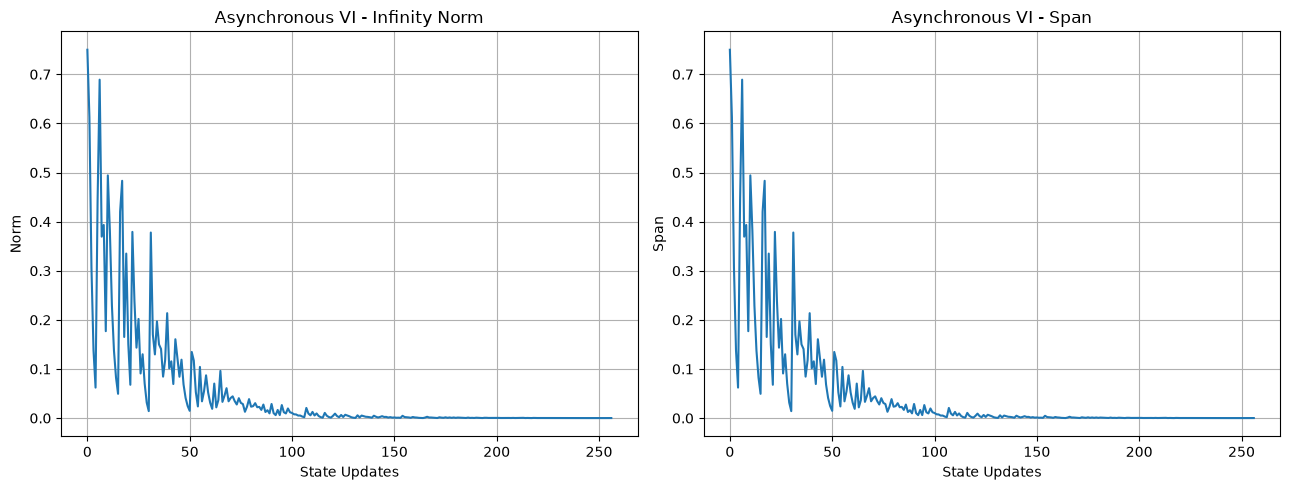

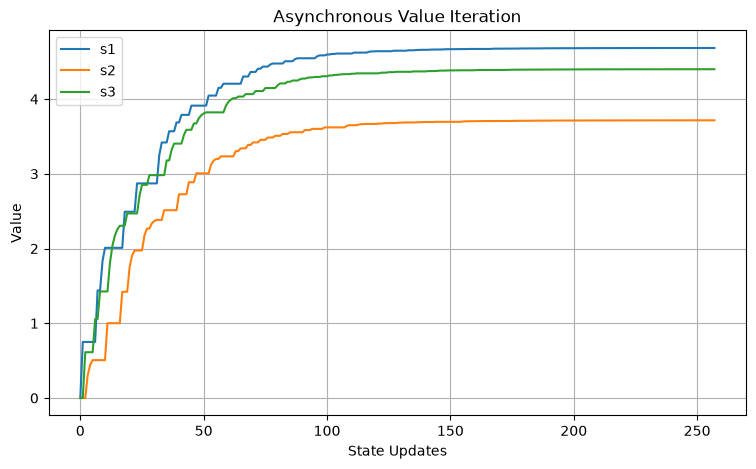

In [6]:

# ==================================================
# (d) 异步值迭代 Asynchronous Value Iteration
# ==================================================

def asynchronous_value_iteration(
    epsilon=0.01,
    max_iter=100000,
    seed=42
):

    # 初始化价值函数
    V = np.zeros(n_states)

    # 设置随机数生成器
    rng = np.random.default_rng(seed)

    # 保存迭代过程
    value_history = [V.copy()]
    norm_history = []
    span_history = []
    residual_history = []

    for k in range(max_iter):

        V_old = V.copy()

        # ------------------------------------------
        # 1. 均匀随机选择一个状态
        # ------------------------------------------

        s = rng.integers(0, n_states)

        # ------------------------------------------
        # 2. 只更新被选中的状态
        # ------------------------------------------

        Q = R[s] + gamma * P[:, s, :] @ V

        V[s] = np.max(Q)

        # ------------------------------------------
        # 3. 记录本次更新的变化
        # ------------------------------------------

        delta = V - V_old

        norm_delta = np.max(np.abs(delta))

        span_delta = np.max(delta) - np.min(delta)

        norm_history.append(norm_delta)
        span_history.append(span_delta)

        value_history.append(V.copy())

        # ------------------------------------------
        # 4. 计算 Bellman 残差
        # ------------------------------------------

        residual = bellman(V) - V

        residual_norm = np.max(np.abs(residual))

        residual_history.append(residual_norm)

        # 价值函数误差界
        error_bound = residual_norm / (1 - gamma)

        # 当前价值函数对应的贪心策略性能损失界
        policy_bound = (
            2 * gamma / (1 - gamma) * error_bound
        )

        if policy_bound <= epsilon:
            break

    # ------------------------------------------
    # 5. 提取最终贪心策略
    # ------------------------------------------

    policy = np.argmax(get_Q(V), axis=1)

    return (
        V,
        policy,
        np.array(norm_history),
        np.array(span_history),
        np.array(value_history),
        np.array(residual_history)
    )


# ==================================================
# 6. 执行异步值迭代
# ==================================================

epsilon = 0.01

result_async = asynchronous_value_iteration(
    epsilon=epsilon,
    max_iter=100000,
    seed=42
)

V_async = result_async[0]
policy_async = result_async[1]


# ==================================================
# 7. 输出结果
# ==================================================

print("\n========== Asynchronous Value Iteration ==========")

print("最优价值函数估计：")
print(V_async)

print("\n最终贪心策略：")

for i in range(n_states):
    print(states[i], ":", actions[policy_async[i]])

print("\n总更新次数：", len(result_async[2]))

print("\n最终 Bellman 残差：")
print(result_async[5][-1])

print("\n最终误差界：")
print(result_async[5][-1] / (1-gamma))


# ==================================================
# 8. 绘制范数和 Span
# ==================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(result_async[2])
axes[0].set_title("Asynchronous VI - Infinity Norm")
axes[0].set_xlabel("State Updates")
axes[0].set_ylabel("Norm")
axes[0].grid()

axes[1].plot(result_async[3])
axes[1].set_title("Asynchronous VI - Span")
axes[1].set_xlabel("State Updates")
axes[1].set_ylabel("Span")
axes[1].grid()

plt.tight_layout()
plt.show()


# ==================================================
# 9. 绘制三个状态的价值函数变化
# ==================================================

plt.figure(figsize=(9, 5))

for i in range(n_states):
    plt.plot(
        result_async[4][:, i],
        label=states[i]
    )

plt.xlabel("State Updates")
plt.ylabel("Value")
plt.title("Asynchronous Value Iteration")
plt.legend()
plt.grid()
plt.show()


In [8]:
gamma = 0.9
n_states = 3
n_actions = 2

# P[a, s, s_next]
# a=0: a_{i,1}
# a=1: a_{i,2}

P = np.array([
    [
        [0,   1/2, 1/2],
        [1/4, 1/2, 1/4],
        [1/6, 1/6, 2/3]
    ],
    [
        [1/2, 1/4, 1/4],
        [1/6, 2/3, 1/6],
        [1/8, 1/8, 3/4]
    ]
], dtype=float)

# 期望即时奖励 R[s, a]
R = np.array([
    [-1.5,  0.75],
    [ 0.0,  0.00],
    [ 0.5, -0.375]
], dtype=float)


# ============================================================
# 通用函数
# ============================================================

def get_Q(V):
    """
    Q[s,a] = R[s,a] + gamma * sum P[a,s,s'] * V[s']
    """
    Q = np.zeros((n_states, n_actions))

    for s in range(n_states):
        for a in range(n_actions):
            Q[s, a] = R[s, a] + gamma * P[a, s] @ V

    return Q


def bellman(V):
    """Bellman 最优算子 TV"""
    return np.max(get_Q(V), axis=1)


def policy_evaluation(policy):
    """
    精确策略评估：
    V^pi = R^pi + gamma * P^pi * V^pi
    """
    P_pi = np.array([
        P[policy[s], s]
        for s in range(n_states)
    ])

    R_pi = np.array([
        R[s, policy[s]]
        for s in range(n_states)
    ])

    V_pi = np.linalg.solve(
        np.eye(n_states) - gamma * P_pi,
        R_pi
    )

    return V_pi


def policy_name(policy):
    """将策略转换为题目中的动作名称"""
    return [
        f"a{i+1},{policy[i]+1}"
        for i in range(n_states)
    ]


# ============================================================
# (e) 带决策排除的值迭代
# ============================================================

def decision_elimination_vi(epsilon=1e-6, max_iter=10000):

    V = np.zeros(n_states)

    # active[s,a] = True 表示该动作尚未被排除
    active = np.ones((n_states, n_actions), dtype=bool)

    value_history = [V.copy()]
    residual_history = []
    eliminated_history = []

    for k in range(max_iter):

        Q = get_Q(V)

        # Bellman 残差
        residual = np.max(np.abs(bellman(V) - V))

        # 价值函数误差上界
        error_bound = residual / (1 - gamma)

        # -------- 决策排除 --------
        for s in range(n_states):

            candidates = np.where(active[s])[0]

            if len(candidates) <= 1:
                continue

            for a in candidates:

                others = candidates[candidates != a]

                if len(others) == 0:
                    continue

                # 动作 a 的 Q 值上界
                upper_a = Q[s, a] + gamma * error_bound

                # 其他动作中最大的 Q 值下界
                best_lower = np.max(
                    Q[s, others] - gamma * error_bound
                )

                # 严格证明动作 a 不可能最优
                if upper_a < best_lower:
                    active[s, a] = False

        # -------- 在保留动作中进行值迭代 --------
        V_new = np.zeros(n_states)

        for s in range(n_states):
            candidates = np.where(active[s])[0]
            V_new[s] = np.max(Q[s, candidates])

        V = V_new.copy()
        value_history.append(V.copy())

        # 更新后的 Bellman 残差
        residual = np.max(np.abs(bellman(V) - V))

        residual_history.append(residual)
        eliminated_history.append(np.sum(~active))

        # 停止条件
        if residual / (1 - gamma) <= epsilon:
            break

    # 最终策略
    Q_final = get_Q(V)
    policy = np.argmax(
        np.where(active, Q_final, -np.inf),
        axis=1
    )

    return {
        "V": V,
        "policy": policy,
        "active": active,
        "value_history": np.array(value_history),
        "residual_history": np.array(residual_history),
        "eliminated_history": np.array(eliminated_history)
    }


# ============================================================
# (f-1) 标准策略迭代
# ============================================================

def standard_policy_iteration(max_iter=1000):

    # 初始策略：每个状态均选择动作1
    policy = np.zeros(n_states, dtype=int)

    value_history = []
    policy_history = []

    for k in range(max_iter):

        # 1. 策略评估
        V = policy_evaluation(policy)

        value_history.append(V.copy())
        policy_history.append(policy.copy())

        # 2. 批量策略改进
        Q = get_Q(V)
        new_policy = np.argmax(Q, axis=1)

        # 3. 判断策略是否稳定
        if np.array_equal(new_policy, policy):
            break

        policy = new_policy.copy()

    return {
        "V": V,
        "policy": policy,
        "value_history": np.array(value_history),
        "policy_history": np.array(policy_history),
        "iterations": len(value_history)
    }


# ============================================================
# (f-2) 策略迭代变体
# 发现一个严格改进的决策后，立即重新计算价值函数
# ============================================================

def modified_policy_iteration(max_iter=1000, tol=1e-10):

    policy = np.zeros(n_states, dtype=int)

    value_history = []
    policy_history = []

    improvement_count = 0

    for k in range(max_iter):

        # 1. 策略评估
        V = policy_evaluation(policy)

        value_history.append(V.copy())
        policy_history.append(policy.copy())

        # 2. 计算动作价值
        Q = get_Q(V)

        improved = False

        # 按状态顺序寻找第一个严格改进的决策
        for s in range(n_states):

            current_action = policy[s]
            best_action = np.argmax(Q[s])

            # 严格改进
            if Q[s, best_action] > Q[s, current_action] + tol:

                policy[s] = best_action

                improvement_count += 1
                improved = True

                # 发现一个严格改进后立即重新评估
                break

        # 没有严格改进，说明策略已经最优
        if not improved:
            break

    return {
        "V": V,
        "policy": policy,
        "value_history": np.array(value_history),
        "policy_history": np.array(policy_history),
        "iterations": len(value_history),
        "improvement_count": improvement_count
    }


# ============================================================
# 运行 (e)
# ============================================================

result_e = decision_elimination_vi(epsilon=1e-6)

print("=" * 55)
print("(e) 带决策排除的值迭代")
print("=" * 55)

print("最优价值函数：")
print(result_e["V"])

print("最优策略：")
print(policy_name(result_e["policy"]))

print("最终保留动作：")
print(result_e["active"])

print("排除动作数量：",
      result_e["eliminated_history"][-1])

print("迭代次数：",
      len(result_e["residual_history"]))


(e) 带决策排除的值迭代
最优价值函数：
[4.68386997 3.71612804 4.39999901]
最优策略：
['a1,2', 'a2,1', 'a3,1']
最终保留动作：
[[False  True]
 [ True False]
 [ True False]]
排除动作数量： 3
迭代次数： 145



(f) 标准策略迭代
最优价值函数：
[4.68387097 3.71612903 4.4       ]
最优策略：
['a1,2', 'a2,1', 'a3,1']
策略评估次数： 3

(f) 策略迭代变体
最优价值函数：
[4.68387097 3.71612903 4.4       ]
最优策略：
['a1,2', 'a2,1', 'a3,1']
策略评估次数： 2
严格改进次数： 1

策略迭代结果比较
价值函数是否一致： True
策略是否一致： True


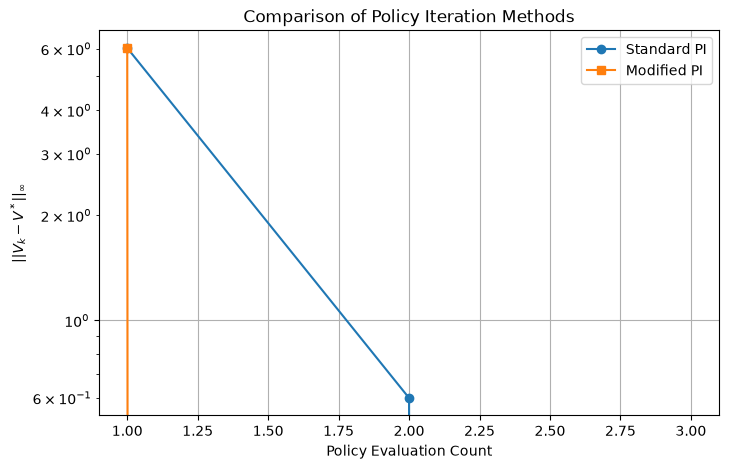

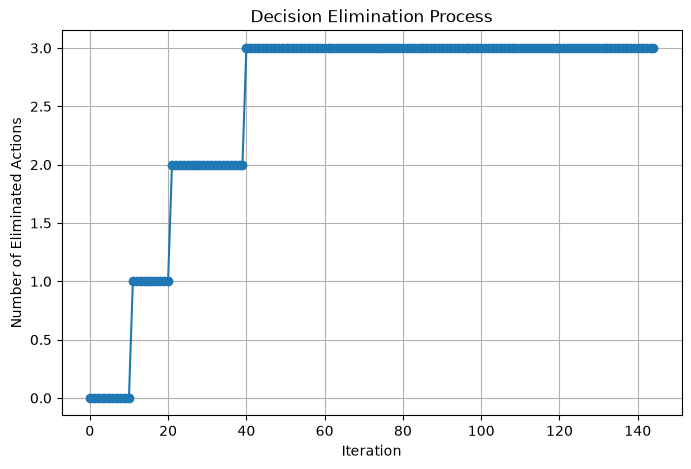

In [9]:
# ============================================================
# 运行 (f)
# ============================================================

result_f1 = standard_policy_iteration()
result_f2 = modified_policy_iteration()

print("\n" + "=" * 55)
print("(f) 标准策略迭代")
print("=" * 55)

print("最优价值函数：")
print(result_f1["V"])

print("最优策略：")
print(policy_name(result_f1["policy"]))

print("策略评估次数：",
      result_f1["iterations"])


print("\n" + "=" * 55)
print("(f) 策略迭代变体")
print("=" * 55)

print("最优价值函数：")
print(result_f2["V"])

print("最优策略：")
print(policy_name(result_f2["policy"]))

print("策略评估次数：",
      result_f2["iterations"])

print("严格改进次数：",
      result_f2["improvement_count"])


# ============================================================
# 比较两种策略迭代
# ============================================================

print("\n" + "=" * 55)
print("策略迭代结果比较")
print("=" * 55)

print("价值函数是否一致：",
      np.allclose(result_f1["V"], result_f2["V"]))

print("策略是否一致：",
      np.array_equal(
          result_f1["policy"],
          result_f2["policy"]
      ))


# ============================================================
# 收敛曲线
# ============================================================

def plot_pi_convergence(result1, result2):

    V_star = result1["V"]

    error1 = [
        np.max(np.abs(V - V_star))
        for V in result1["value_history"]
    ]

    error2 = [
        np.max(np.abs(V - V_star))
        for V in result2["value_history"]
    ]

    plt.figure(figsize=(8, 5))

    plt.plot(
        range(1, len(error1) + 1),
        error1,
        marker='o',
        label='Standard PI'
    )

    plt.plot(
        range(1, len(error2) + 1),
        error2,
        marker='s',
        label='Modified PI'
    )

    plt.xlabel("Policy Evaluation Count")
    plt.ylabel(r"$||V_k-V^*||_\infty$")
    plt.title("Comparison of Policy Iteration Methods")

    plt.yscale("log")
    plt.legend()
    plt.grid(True)
    plt.show()


plot_pi_convergence(result_f1, result_f2)


# ============================================================
# 决策排除过程可视化
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    result_e["eliminated_history"],
    marker='o'
)

plt.xlabel("Iteration")
plt.ylabel("Number of Eliminated Actions")
plt.title("Decision Elimination Process")
plt.grid(True)
plt.show()
